# EDA 03 — диагностика sampling bias

Ноутбук исследует пространственную неоднородность известных месторождений и доступность данных. Модель может отражать не только геологию, но и историю поисков: доступность территории, плотность картирования и качество исходных слоёв. Дорожные/инфраструктурные признаки — диагностические переменные; не включать их в predictor set автоматически.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT=Path.cwd()
while ROOT!=ROOT.parent and not (ROOT/"data"/"processed").exists(): ROOT=ROOT.parent
path=ROOT/"data"/"processed"/"features_table_geo.csv"
if not path.exists(): path=Path("../../data/processed/features_table_geo.csv")
df=pd.read_csv(path)
P=df[df.is_deposit==1].copy(); U=df[df.is_deposit==0].copy()
print("Rows",len(df),"known deposits",len(P),"folds",sorted(df.fold_id.dropna().unique()))
display(df.groupby("fold_id").agg(cells=("is_deposit","size"),positives=("is_deposit","sum"),positive_share=("is_deposit","mean")))

Rows 35694 known deposits 11 folds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


,cells,positives,positive_share
fold_id,,,
0,4874,1,0.000205
1,7273,2,0.000275
2,3359,2,0.000595
3,17250,5,0.000290
4,2938,1,0.000340


## 1. Пространственная концентрация и фолды

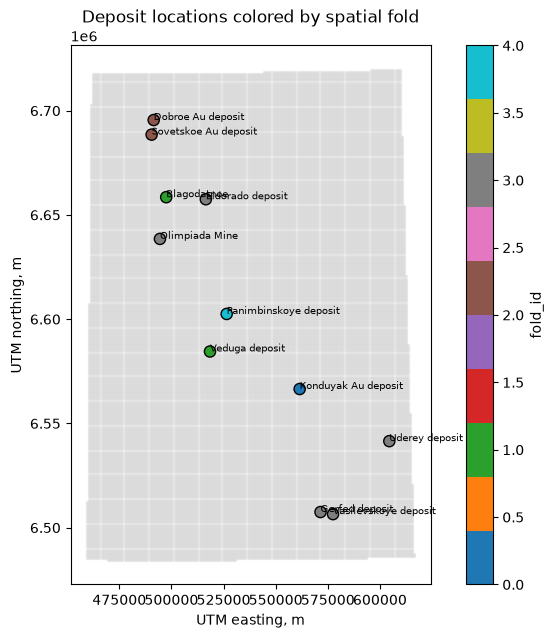

Positive count per fold:


,n_positive
fold_id,
0,1
1,2
2,2
3,5
4,1


In [2]:
fig,ax=plt.subplots(figsize=(9,7)); ax.scatter(U.x,U.y,s=2,c="lightgrey",alpha=.4,label="Unlabeled")
sc=ax.scatter(P.x,P.y,c=P.fold_id,cmap="tab10",s=65,edgecolor="black",label="Known deposits")
for _,r in P.iterrows(): ax.annotate(str(r.get("deposit_name","")),(r.x,r.y),fontsize=7)
ax.set_aspect("equal"); ax.set_title("Deposit locations colored by spatial fold"); ax.set_xlabel("UTM easting, m"); ax.set_ylabel("UTM northing, m"); plt.colorbar(sc,ax=ax,label="fold_id"); plt.show()
print("Positive count per fold:"); display(P.groupby("fold_id").size().reindex(sorted(df.fold_id.dropna().unique()),fill_value=0).rename("n_positive").to_frame())

### Выводы по качеству данных

Таблица содержит 35 694 ячейки, из которых 11 имеют
статус известных месторождений, а 35 683 относятся
к Unlabeled background.

Дубликаты строк и координат не обнаружены.
Координаты находятся в ожидаемом диапазоне тестовой
площади Енисейского кряжа.

Все числовые предикторы заполнены. Единственный
геологический признак с пропусками — lithology_group:
406 ячеек (1,14%).

Пропуск литологии не следует автоматически трактовать
как отдельный тип пород. Перед обучением нужно проверить
источник пропусков и решить, использовать ли отдельную
категорию Unknown или исключить эти ячейки из расчёта
конкретного признака.

**Ограничение:** 11 известных месторождений — очень
небольшая выборка относительно 35 694 ячеек. Все
дальнейшие сравнения имеют exploratory-характер.

## 2. Простейшая диагностика кластеризации

Оценим ближайшее расстояние между известными месторождениями и их расстояние до центра области. Это не тест геологической кластеризации: результат зависит от границ study area и неполноты инвентаря.

In [4]:
from scipy.spatial.distance import pdist, squareform
if len(P) > 1:
    D = squareform(pdist(P[["x", "y"]].to_numpy()))
    np.fill_diagonal(D, np.inf)
    P["nearest_known_deposit_km"] = D.min(axis=1) / 1000
    display(P[["deposit_name", "fold_id", "nearest_known_deposit_km"]].sort_values("nearest_known_deposit_km"))
    print("Median nearest-known distance, km:", P.nearest_known_deposit_km.median())
center = df[["x", "y"]].mean().to_numpy()
P["distance_to_area_center_km"] = np.linalg.norm(P[["x", "y"]].to_numpy() - center, axis=1) / 1000
display(P[["deposit_name", "distance_to_area_center_km"]])

,deposit_name,fold_id,nearest_known_deposit_km
27280,Vasilevskoye deposit,3,6.082763
25877,Gerfed deposit,3,6.082763
7118,Sovetskoe Au deposit,2,7.071068
7359,Dobroe Au deposit,2,7.071068
8726,Blagodatnoe,1,19.026298
13171,Eldorado deposit,3,19.026298
15456,Panimbinskoye deposit,4,19.697716
13566,Veduga deposit,1,19.697716
8004,Olimpiada Mine,3,20.223748
33631,Uderey deposit,3,44.204072


Median nearest-known distance, km: 19.02629759044045


,deposit_name,distance_to_area_center_km
7118,Sovetskoe Au deposit,99.467034
7359,Dobroe Au deposit,105.280280
8004,Olimpiada Mine,56.869357
8726,Blagodatnoe,70.083904
13171,Eldorado deposit,60.545381
13566,Veduga deposit,24.242445
15456,Panimbinskoye deposit,10.464280
23596,Konduyak Au deposit,42.003753
25877,Gerfed deposit,99.225172
27280,Vasilevskoye deposit,102.398235


### Выводы по качеству данных

Таблица содержит 35 694 ячейки, из которых 11 имеют
статус известных месторождений, а 35 683 относятся
к Unlabeled background.

Дубликаты строк и координат не обнаружены.
Координаты находятся в ожидаемом диапазоне тестовой
площади Енисейского кряжа.

Все числовые предикторы заполнены. Единственный
геологический признак с пропусками — lithology_group:
406 ячеек (1,14%).

Пропуск литологии не следует автоматически трактовать
как отдельный тип пород. Перед обучением нужно проверить
источник пропусков и решить, использовать ли отдельную
категорию Unknown или исключить эти ячейки из расчёта
конкретного признака.

**Ограничение:** 11 известных месторождений — очень
небольшая выборка относительно 35 694 ячеек. Все
дальнейшие сравнения имеют exploratory-характер.

## 3. Прокси качества/изученности

Если в таблице нет расстояний до дорог, населённых пунктов, геологических маршрутов или плотности наблюдений, их нельзя восстановить из этих шести геологических признаков. Ниже — проверка наличия таких колонок и готовая точка расширения.

In [5]:
access_candidates=[c for c in df.columns if any(k in c.lower() for k in ["road","settlement","town","survey","mapping","sample","observation","access"])]
print("Potential access / exploration proxy columns:",access_candidates or "не найдены")
quality_candidates=[c for c in df.columns if any(k in c.lower() for k in ["coverage","nodata","quality","resolution","source"])]
print("Potential data quality columns:",quality_candidates or "не найдены")
if access_candidates:
 for col in access_candidates:
  print("\n",col); display(df.groupby("is_deposit")[col].describe())
else:
 print("Для полноценной диагностики добавьте независимый слой дорог/населённых пунктов/плотности поисковых работ и вычислите расстояния в метрической CRS.")

Potential access / exploration proxy columns: не найдены
Potential data quality columns: не найдены
Для полноценной диагностики добавьте независимый слой дорог/населённых пунктов/плотности поисковых работ и вычислите расстояния в метрической CRS.


### Ограничения диагностики sampling bias

В текущей таблице отсутствуют независимые показатели
доступности территории и интенсивности геологических
исследований.

Не найдены признаки расстояния до дорог и населённых
пунктов, плотности поисковых работ, количества
геологических наблюдений или качества покрытия.

Поэтому пока нельзя проверить, не отражает ли
распределение известных месторождений историю
геологической изученности территории.

Для полноценной диагностики необходимо добавить
независимые инфраструктурные и поисковые слои.

Эти переменные следует использовать прежде всего
для анализа sampling bias, а не автоматически
включать в геологический predictor set.

## 4. Чувствительность к фоновому набору

В PU постановке Unlabeled background — приближение доступной территории, а не набор отрицательных примеров. Сравните фон по пространственным зонам/подвыборкам в отдельном эксперименте. Не удаляйте ячейки около месторождений без геологического обоснования: это меняет базовую частоту и смысл WoE.

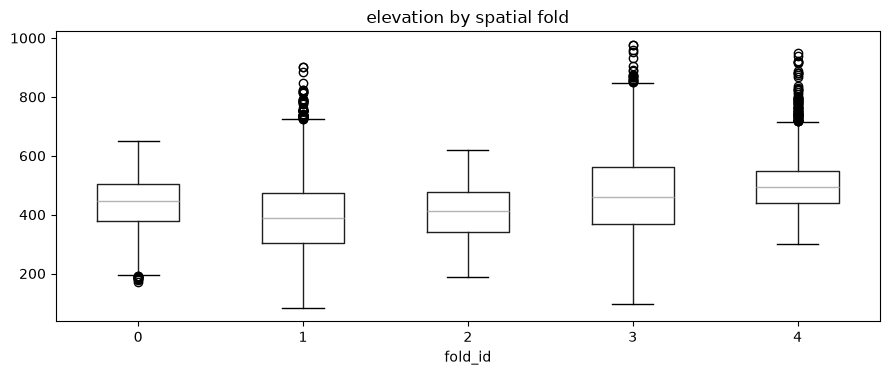

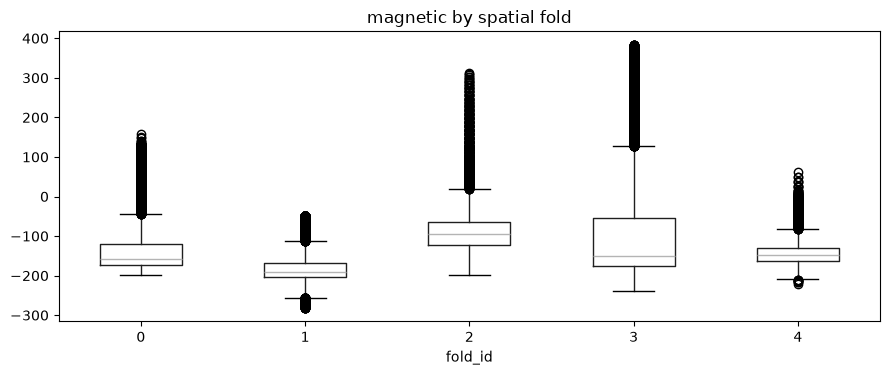

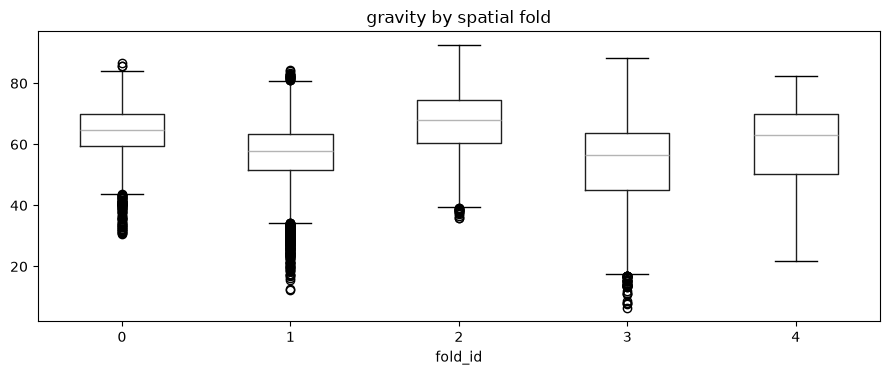

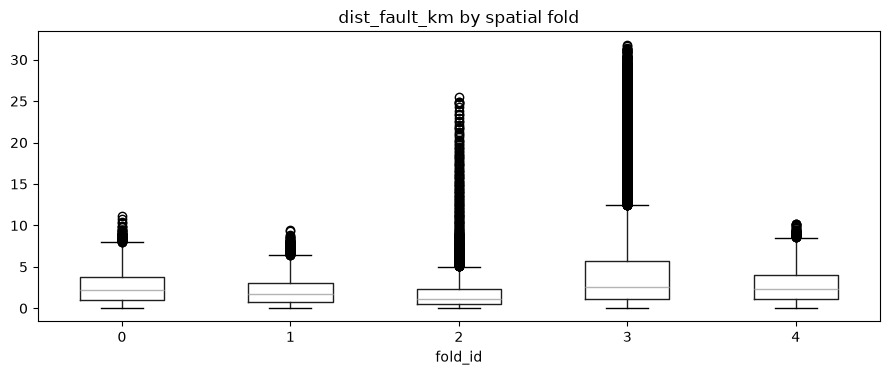

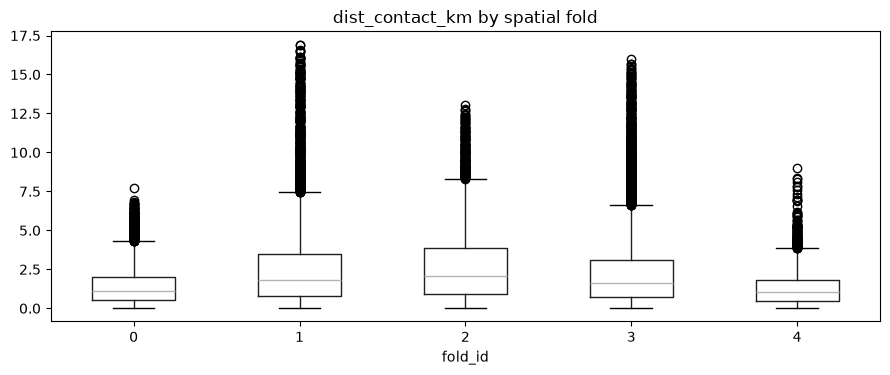

In [6]:
# Диагностические распределения признаков по fold: различия могут указывать на spatial/domain shift
cols=[c for c in ["elevation","magnetic","gravity","dist_fault_km","dist_contact_km"] if c in df]
for col in cols:
 fig,ax=plt.subplots(figsize=(9,4))
 df.boxplot(column=col,by="fold_id",ax=ax,grid=False)
 ax.set_title(f"{col} by spatial fold"); ax.set_xlabel("fold_id"); plt.suptitle(""); plt.tight_layout(); plt.show()

## 5. Итоговые выводы sampling bias

1. Все пять spatial folds содержат Positive, но их
   распределение неравномерно.
2. Известные месторождения демонстрируют отдельные
   локальные группы.
3. Расстояние до ближайшего известного месторождения
   не позволяет доказать статистическую кластеризацию.
4. Независимых прокси изученности и доступности
   территории пока нет.

### Следующие действия

- Проверить пространственную неоднородность покрытия
  исходных геологических и геофизических слоёв.
- Получить дороги, населённые пункты и доступные
  данные о геологических исследованиях.
- Проверить связь известных месторождений
  с доступностью территории.
- Провести sensitivity analysis к выбору
  Unlabeled background.

До появления этих данных sampling bias считается
неустранённым ограничением проекта.